<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_1_Yield_Prediction/Machine_Learning_Pipeline/Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Google Drive to get the final dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Import Libraries
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
final_data_path = '/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data.csv'

# Load final data
final_data = pd.read_csv(final_data_path)

In [4]:
final_data.head()

,Year,Month,YPH,T200,UT925,U709,Epson Salt,Dolomite,Urea,Zinc,...,temperature_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,relative_humidity_2m_mean,precipitation_sum,rain_sum,sunshine_duration,wind_speed_10m_max,wind_speed_10m_mean,et0_fao_evapotranspiration
0,2017,Jan,90.0,600.0,450.0,2000.0,0.0,0.0,0.0,0.0,...,18.412903,93.516129,60.483871,76.903226,201.3,201.3,1037724.72,8.451613,4.516129,3.479032
1,2017,Feb,124.0,0.0,1700.0,0.0,0.0,0.0,0.0,0.0,...,18.410714,97.642857,64.357143,83.428571,151.6,151.6,994468.11,7.542857,3.889286,3.722500
2,2017,Mar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.248387,98.838710,73.677419,88.451613,221.3,221.3,1113625.83,8.212903,4.074194,3.654516
3,2017,Apr,149.0,0.0,12900.0,3250.0,166.5,27350.0,166.5,166.5,...,20.036667,99.533333,77.666667,90.933333,152.5,152.5,1106964.18,9.070000,4.480000,3.620333
4,2017,May,125.0,0.0,12650.0,13250.0,163.0,0.0,163.0,163.0,...,19.919355,99.741935,84.612903,94.290323,681.7,681.7,807927.15,10.612903,6.793548,2.560968


### Dataset structure

In [5]:
final_data.shape

(108, 25)

### Data types inspection

In [6]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Year                        108 non-null    int64  
 1   Month                       108 non-null    object 
 2   YPH                         96 non-null     float64
 3   T200                        96 non-null     float64
 4   UT925                       96 non-null     float64
 5   U709                        96 non-null     float64
 6   Epson Salt                  96 non-null     float64
 7   Dolomite                    96 non-null     float64
 8   Urea                        96 non-null     float64
 9   Zinc                        96 non-null     float64
 10  Compost                     96 non-null     float64
 11  BioShakthi                  96 non-null     float64
 12  BioShield                   96 non-null     float64
 13  temperature_2m_max          108 non

### Missing value matrix

In [10]:
final_data.isna().sum()

,0
Year,0
Month,0
YPH,12
T200,12
UT925,12
U709,12
Epson Salt,12
Dolomite,12
Urea,12
Zinc,12


In [8]:
# Check empty columns
rows_with_nan = final_data[final_data.isna().any(axis=1)]
display(rows_with_nan)

,Year,Month,YPH,T200,UT925,U709,Epson Salt,Dolomite,Urea,Zinc,...,temperature_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,relative_humidity_2m_mean,precipitation_sum,rain_sum,sunshine_duration,wind_speed_10m_max,wind_speed_10m_mean,et0_fao_evapotranspiration
2,2017,Mar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.248387,98.838710,73.677419,88.451613,221.3,221.3,1113625.83,8.212903,4.074194,3.654516
14,2018,Mar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.493548,98.322581,74.161290,87.870968,291.8,291.8,1055610.24,7.019355,3.438710,3.499677
24,2019,Jan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.329032,97.903226,67.741935,84.774194,164.0,164.0,1133005.03,7.477419,3.674194,3.500000
65,2022,Jun,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.840000,99.900000,85.833333,95.300000,340.9,340.9,630538.37,12.756667,8.823333,2.356667
84,2024,Jan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.070968,97.838710,71.806452,86.903226,264.4,264.4,1012658.17,6.896774,3.493548,3.374839
85,2024,Feb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.641379,95.517241,67.517241,82.689655,102.8,102.8,1130903.68,6.972414,3.596552,4.201034
89,2024,Jun,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.606667,99.833333,85.366667,95.033333,445.8,445.8,812936.45,13.696667,9.690000,2.596667
96,2025,Jan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.841935,98.838710,76.419355,90.967742,421.7,421.7,766194.33,5.974194,2.745161,2.606452
97,2025,Feb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.857143,98.285714,56.857143,82.142857,91.8,91.8,1088518.59,8.285714,3.707143,4.205357
105,2025,Oct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,19.151613,99.193548,73.806452,90.129032,389.3,389.3,880189.12,10.158065,5.190323,3.026774


**Interpretation**

The dataset consists of 108 rows in total. It has 25 columns which includes year, month, fertilizers and weather data. Other than month all the columns are numerical. The dataset has some missing rows(12). While weather variables are complete for all months, yield and fertilizer records are missing for certain periods, creating partially observed samples.

Missing values occur simultaneously in yield and fertilizer variables, while weather data is present. This suggests operational or recording gaps rather than sensor failure, indicating a structured missingness pattern.


## Target Variable

### Descriptive Statistics of YPH

In [4]:
# Descriptive statistics
yp_stats = final_data['YPH'].describe()
skewness = final_data['YPH'].skew()

print("=== YPH Descriptive Statistics ===")
print(yp_stats)
print(f"Skewness: {skewness:.2f}")

=== YPH Descriptive Statistics ===
count     96.000000
mean     117.010417
std       33.268128
min       42.000000
25%       97.000000
50%      115.000000
75%      137.000000
max      214.000000
Name: YPH, dtype: float64
Skewness: 0.27


### Histogram of YPH

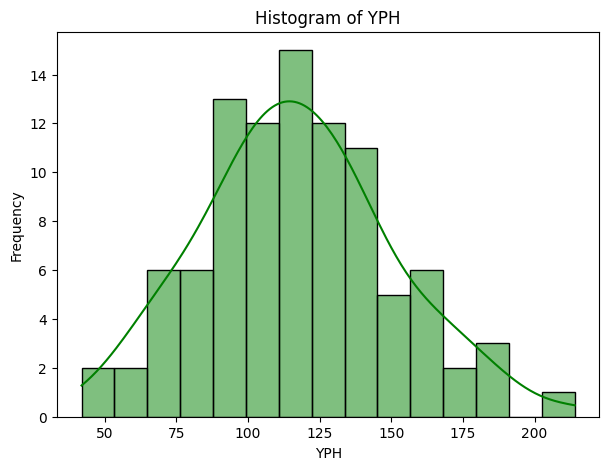

In [5]:
plt.figure(figsize=(7,5))
sns.histplot(final_data['YPH'], bins=15, kde=True, color='green')
plt.title('Histogram of YPH')
plt.xlabel('YPH')
plt.ylabel('Frequency')
plt.show()

### Boxplot of YPH

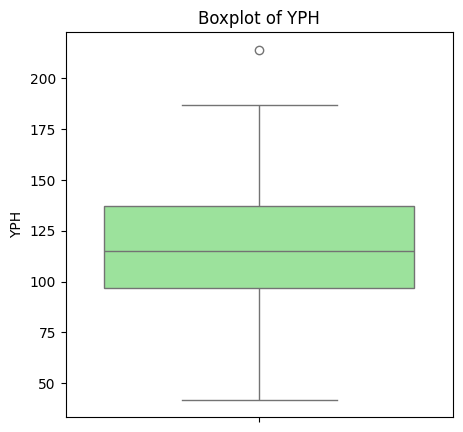

In [6]:
plt.figure(figsize=(5,5))
sns.boxplot(y=final_data['YPH'], color='lightgreen')
plt.title('Boxplot of YPH')
plt.ylabel('YPH')
plt.show()

### YPH Over Time

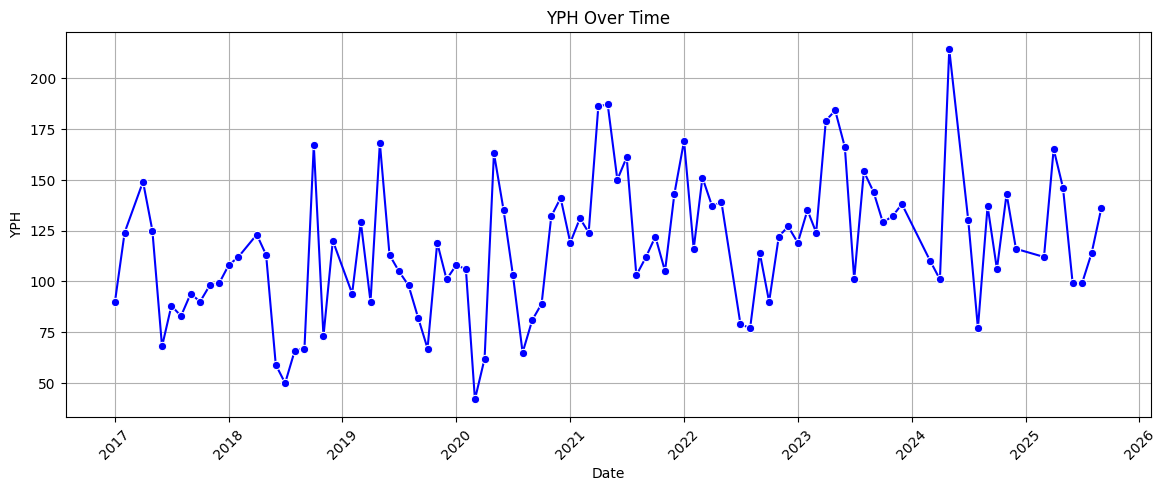

In [7]:
# Convert Month to numeric
final_data['Month_num'] = final_data['Month'].astype(str).str.zfill(2)  # pad with zero

# Create Date column
final_data['Date'] = pd.to_datetime(final_data['Year'].astype(str) + '-' + final_data['Month_num'] + '-01')

plt.figure(figsize=(14,5))
sns.lineplot(data=final_data, x='Date', y='YPH', marker='o', color='blue')
plt.title('YPH Over Time')
plt.xlabel('Date')
plt.ylabel('YPH')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

**Interpretation**
1.   Descriptive Statistics
  *   The mean YPH is 117 units, with a standard deviation of 33, showing moderate variability.
  *   Minimum and maximum yields are 42 and 214, indicating occasional extreme high and low yields.
  *   Skewness is 0.27, meaning the distribution is slightly right-skewed but nearly symmetric.
2.   Distribution (Histogram & Boxplot)
  *   YPH distribution is approximately normal, with most values concentrated between 75 and 160.
  *   The median (115) is close to the mean, confirming symmetry.
  *   A few high-value observations (≈200–214) exist, considered rare high yields, not extreme outliers.
  *   Boxplot confirms moderate variability and small number of high-value points.
3.   Time Series Trend
  *   YPH fluctuates over time, showing seasonal variation and some long-term trends.
  *   Peaks and dips correspond to seasonal or environmental factors.
  *   No consistent monotonic trend is observed, but there is clear temporal dependence, indicating that lag features could improve predictions.



## YPH by Month and YPH by Year

### Average YPH by Month

/tmp/ipython-input-2855020229.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_avg = final_data.groupby('Month')['YPH'].mean().reset_index()
/tmp/ipython-input-2855020229.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_avg, x='Month', y='YPH', palette='viridis')


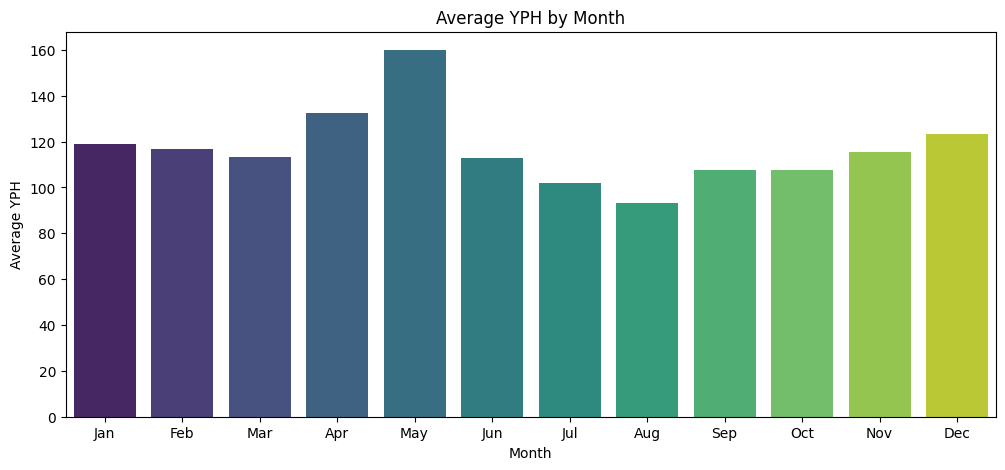

In [8]:
# Ensure Month is categorical with correct order
months_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
final_data['Month'] = pd.Categorical(final_data['Month'], categories=months_order, ordered=True)

# Compute monthly average YPH
monthly_avg = final_data.groupby('Month')['YPH'].mean().reset_index()

plt.figure(figsize=(12,5))
sns.barplot(data=monthly_avg, x='Month', y='YPH', palette='viridis')
plt.title('Average YPH by Month')
plt.xlabel('Month')
plt.ylabel('Average YPH')
plt.show()

### Yearly Trend of YPH

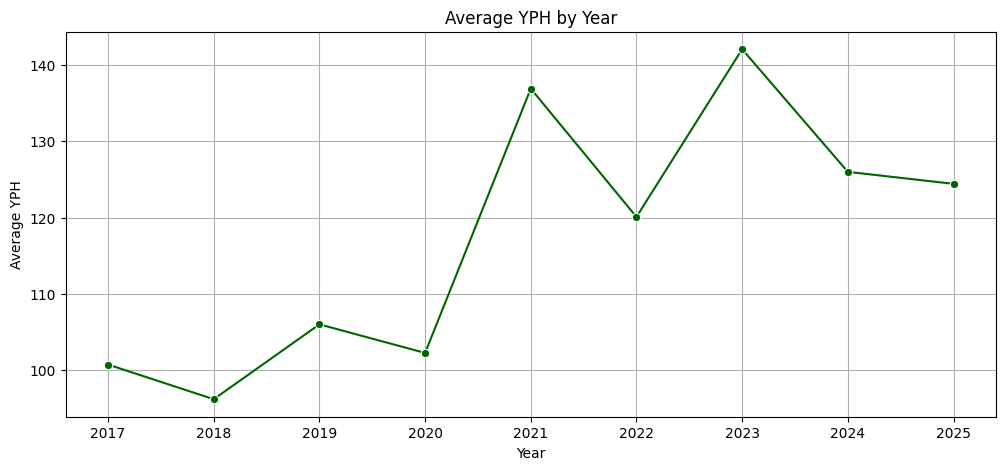

In [9]:
# Compute yearly average YPH
yearly_avg = final_data.groupby('Year')['YPH'].mean().reset_index()

plt.figure(figsize=(12,5))
sns.lineplot(data=yearly_avg, x='Year', y='YPH', marker='o', color='darkgreen')
plt.title('Average YPH by Year')
plt.xlabel('Year')
plt.ylabel('Average YPH')
plt.grid(True)
plt.show()

### Monthly Boxplot (Seasonality & Variability)

/tmp/ipython-input-2158770010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=final_data, x='Month', y='YPH', palette='coolwarm')


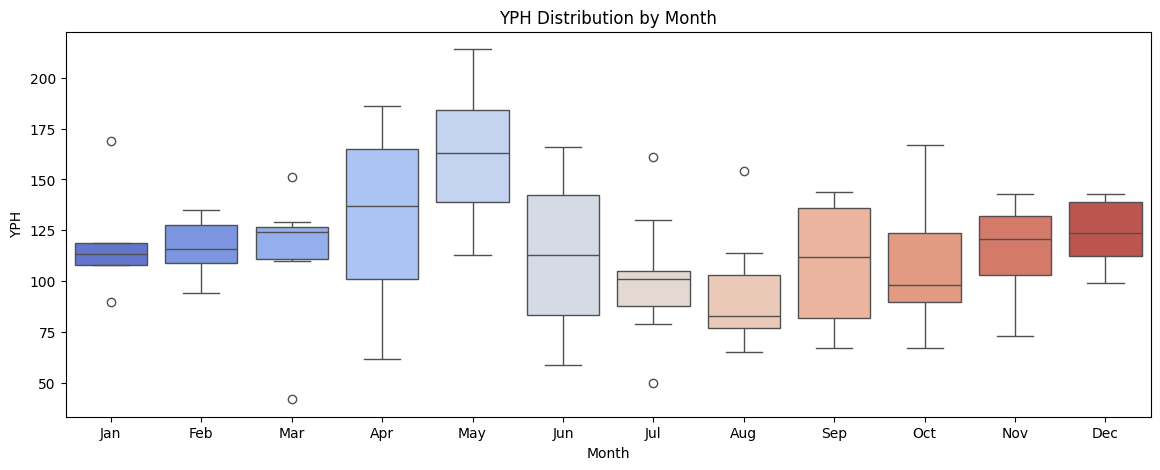

In [10]:
plt.figure(figsize=(14,5))
sns.boxplot(data=final_data, x='Month', y='YPH', palette='coolwarm')
plt.title('YPH Distribution by Month')
plt.xlabel('Month')
plt.ylabel('YPH')
plt.show()

### **Interpretation**
1. Yearly Trend (Average YPH by Year)

      * From 2017 to 2020, YPH is relatively flat, around 100 units.
      * After 2020, there is a sharp upward trend, reaching a peak in 2023 (~142 units).
      * In 2024 and 2025, the yield slightly declines and stabilizes around 125 units.
      * Indicates a long-term improvement in yield with recent stabilization.

2. Seasonal Variation (Average YPH by Month)

    * May is the highest-yielding month, averaging about 160 units.

    * August is the lowest month, averaging under 100 units (~93).

    * Yields gradually recover from September to December.

    * Shows clear seasonal patterns, with consistent peaks and dips each year.

3. Monthly Variability (Boxplots by Month)

    * Months like April, May, June have high volatility — yields fluctuate widely.

    * January and February are very stable, with low variance.

    * Outliers exist: low values in March, high values in July.

    * Suggests some months are more predictable than others, which is important for modeling.

4. Cyclical Patterns & Extreme Spikes (Time Series)

    * Month-to-month data shows a zigzag pattern, confirming seasonal cycles.

    * Single extreme spike in early 2024 exceeds 210 units, the highest in the dataset.

    * Highlights short-term fluctuations that are not visible in yearly averages.

    * Demonstrates the importance of including temporal/lag features in models.

**Key Takeaways for Modeling**

    * Strong seasonality → include month or lag features to improve predictions.

    * High-volatility months → tree-based or robust regression models handle them better.

    * Rare extreme spikes → model needs to be robust to outliers.

    * Year trend → including year as a feature can capture long-term trends.

## Correlation and Feature Analysis

### Correlation Matrix (All Features with YPH)

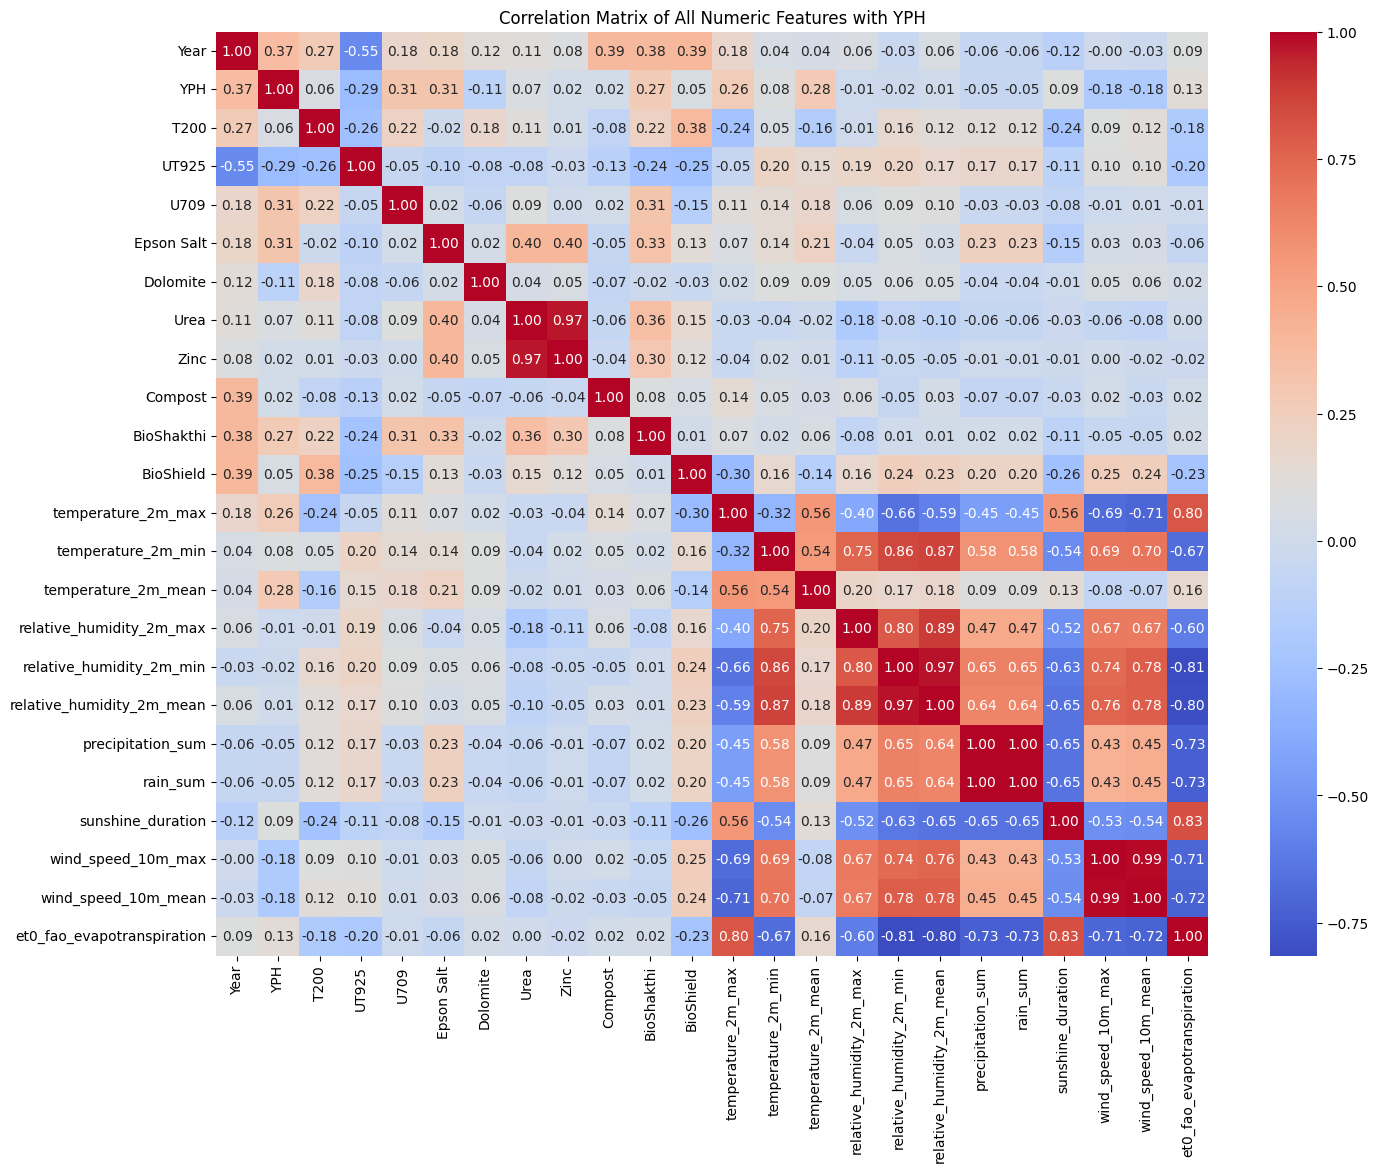

In [14]:
# Create a numeric month column
month_map = {'Jan':1, 'Feb':2, 'Mar':3, 'Apr':4, 'May':5, 'Jun':6,
             'Jul':7, 'Aug':8, 'Sep':9, 'Oct':10, 'Nov':11, 'Dec':12}

final_data['Month_num'] = final_data['Month'].map(month_map)

# Compute correlation using numeric columns only
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = final_data[numeric_cols].corr()

plt.figure(figsize=(16,12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix of All Numeric Features with YPH")
plt.show()

### Correlation of Features Specifically with YPH

In [15]:
# Sort correlation of all features with YPH
yp_corr = corr_matrix['YPH'].sort_values(ascending=False)
print("=== Features Most Positively Correlated with YPH ===")
print(yp_corr.head(10))
print("\n=== Features Most Negatively Correlated with YPH ===")
print(yp_corr.tail(10))

=== Features Most Positively Correlated with YPH ===
YPH                           1.000000
Year                          0.373052
U709                          0.314777
Epson Salt                    0.313765
temperature_2m_mean           0.283763
BioShakthi                    0.272090
temperature_2m_max            0.263193
et0_fao_evapotranspiration    0.131038
sunshine_duration             0.090655
temperature_2m_min            0.080259
Name: YPH, dtype: float64

=== Features Most Negatively Correlated with YPH ===
Compost                      0.017808
relative_humidity_2m_mean    0.005104
relative_humidity_2m_max    -0.011378
relative_humidity_2m_min    -0.016817
rain_sum                    -0.053286
precipitation_sum           -0.053286
Dolomite                    -0.109903
wind_speed_10m_mean         -0.179335
wind_speed_10m_max          -0.183052
UT925                       -0.287469
Name: YPH, dtype: float64


### **Interpretation**
1. Top Positive Influencers on YPH

    * Compost (0.39) and BioShield (0.38) are the strongest positive contributors among supplements.

    * Year (0.37) shows an overall increasing trend in yields over the study period.

    * Future Step: Ensure these are included as key features in the model.

2. Moderate Positive Supplements

    * U709 (0.31), Epson Salt (0.31), BioShakthi (0.27) contribute moderately to YPH.

    * Future Step: Keep these features but consider interactions with top contributors.

3. Weak or Negligible Weather Effects

    * Mean Temperature (0.28) and Maximum Temperature (0.26) have small positive effects.

    * Rain Sum (-0.05) and Minimum Humidity (-0.02) show negligible impact.

    * Future Step: These may still be useful for non-linear ML models like CatBoost.

4. Highly Correlated Feature Pairs (Multicollinearity)

    * Urea & Zinc (0.97) → almost identical information. Keep only one or create a combined feature.

    * Epson Salt & Dolomite (0.40) → moderate correlation. Consider reducing redundancy.

    * Relative Humidity (mean, max, min ≈0.97) → choose one representative or use PCA.

    * Wind speed max & mean (0.99) → very high correlation, keep only one.

    * Future Step: Reduce multicollinearity to improve model interpretability and stability.

5. Negative Correlations to Consider

    * UT925 (-0.29) is negatively correlated with YPH; could be an inhibitor.

    * BioShield & temperature_2m_max (-0.30) shows an interaction effect.

    * et0_fao_evapotranspiration & humidity_2m_min (-0.81) → strong negative relationship; could affect plant stress.

    * Future Step: These features may provide predictive value despite being negative; include in model for learning non-linear patterns.